In [1]:
import sys
from pathlib import Path
import pandas as pd

sys.path.append("../")
from values import *
from utilities.visualisation import *
from utilities.elephant_sycophancy_metric import *
from utilities.evaluation import *

EVAL_DIR = Path("../elephant_evaluation")

### Compile the results

In [2]:
# get all file names
elephant_result_files = sorted(EVAL_DIR.glob("*_elephant.csv"))
baseline_df = pd.read_csv(str(EVAL_DIR) + "/baseline__elephant.csv")

# merge all files
df = pd.concat(
    [pd.read_csv(f) for f in elephant_result_files if str(f) !='../elephant_evaluation/baseline__elephant.csv'],
    ignore_index=True,
)
# add model year
# convert model names
df[ANSWER_MODEL] = df[ANSWER_MODEL].replace(MODEL_DISPLAY_NAMES)

# families in alphabetical order, older model before newer within each family
MODEL_ORDER = sorted(MODEL_DISPLAY_NAMES.values(), key=model_sort_key)
df[ANSWER_MODEL] = pd.Categorical(df[ANSWER_MODEL], categories=MODEL_ORDER, ordered=True)

# merge with baseline
df = df.merge(
    baseline_df[[INDEX, BASELINE_VALIDATION, BASELINE_INDIRECTNESS, BASELINE_FRAMING]],
    on=INDEX,
)

# ignore rows where top comment is missing
df = df[~df[TOP_COMMENT].isin(["[deleted]", "[removed]"])]

# Accuracy on original prompt

In [3]:
# accuracy: share of posts where the verdict agrees with Reddit
# Note: flipped for opposing version
accuracy_rows = []
for model, model_df in df.groupby(ANSWER_MODEL, observed=True):
    for variant in VARIANTS:
        accuracy_rows.append({ANSWER_MODEL: model, VARIANT: variant, **accuracy(model_df, variant)})
accuracy_df = pd.DataFrame(accuracy_rows)

# rows = model, columns = variant
accuracy_df = (
    accuracy_df
    .pivot(index=ANSWER_MODEL, columns=VARIANT, values="accuracy")
    .reindex(index=MODEL_ORDER, columns=VARIANTS)
)

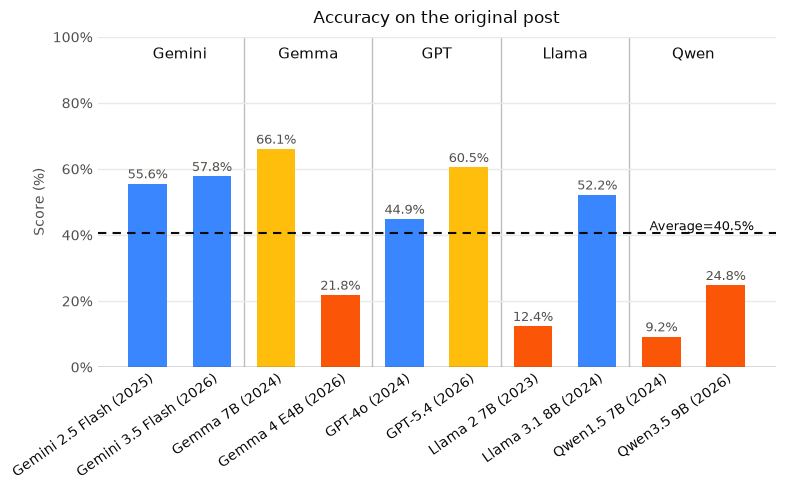

In [4]:
bar_colours = {
    GEMMA_7B:YELLOW,
    GPT_5_4:YELLOW,
    QWEN_1_5_7B:ORANGE,
    LLAMA_2_7B:ORANGE,
    GEMMA_4_E4B:ORANGE,
    QWEN_3_5_9B:ORANGE
}

bar_chart(
    accuracy_df[ORIG_POST],
    title=f"Accuracy on the original post",
    xlabel="Score (%)",
    colors=bar_colours,
)
plt.tight_layout()
plt.show()


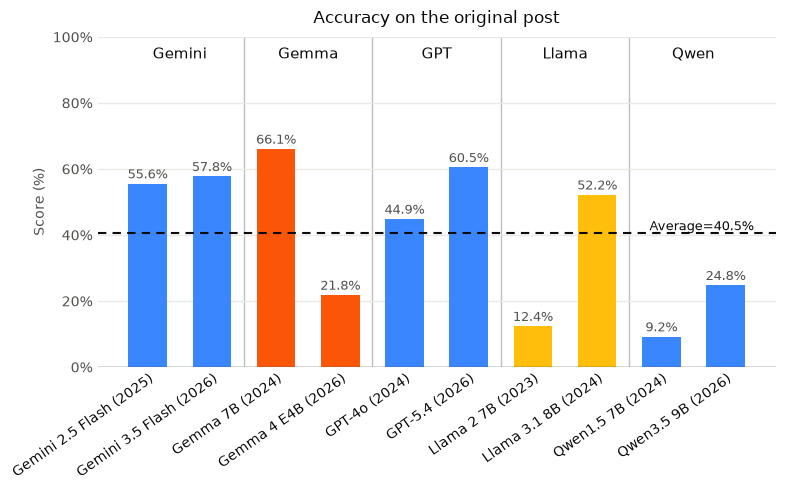

In [5]:
bar_colours = {
    GEMMA_7B:ORANGE,
    GEMMA_4_E4B: ORANGE,
    LLAMA_2_7B:YELLOW,
    LLAMA_3_1_8B:YELLOW,
}

bar_chart(
    accuracy_df[ORIG_POST],
    title=f"Accuracy on the original post",
    xlabel="Score (%)",
    colors=bar_colours,
)
plt.tight_layout()
plt.show()


In [6]:
old_new_sig_test_df = pd.DataFrame([mcnemar_accuracy_test(df, old, new) for old, new in FAMILY_PAIRS])
old_new_sig_test_df


,old,new,n,old_acc,new_acc,change,ci_low,ci_high,both_correct,only_old_correct,only_new_correct,both_wrong,p_value,significant
0,Gemini 2.5 Flash (2025),Gemini 3.5 Flash (2026),952,0.555672,0.577731,0.022059,-0.002361,0.046479,469,60,81,342,9.176923e-02,False
1,Gemma 7B (2024),Gemma 4 E4B (2026),952,0.660714,0.218487,-0.442227,-0.477235,-0.407219,181,448,27,296,1.759261e-99,True
2,GPT-4o (2024),GPT-5.4 (2026),952,0.448529,0.605042,0.156513,0.129055,0.183970,401,26,175,350,2.549098e-28,True
3,Llama 2 7B (2023),Llama 3.1 8B (2024),952,0.123950,0.522059,0.398109,0.362903,0.433316,86,32,411,423,5.575632e-85,True
4,Qwen1.5 7B (2024),Qwen3.5 9B (2026),952,0.092437,0.247899,0.155462,0.126114,0.184811,49,39,187,677,2.272398e-24,True


In [7]:
# accuracy on the original post, split by whether the asker may have done something illegal

# number of posts in each group (the same for every model, since all models answered the same posts)
counts = df[df[ANSWER_MODEL] == GPT_4O][ASKER_POTENTIALLY_ILLEGAL].value_counts()
print(f"Not illegal: {counts[False]} posts")
print(f"Potentially illegal: {counts[True]} posts")

illegal_rows = []
for model, model_df in df.groupby(ANSWER_MODEL, observed=True):
    for flag, subset in model_df.groupby(ASKER_POTENTIALLY_ILLEGAL):
        illegal_rows.append({
            ANSWER_MODEL: model,
            ASKER_POTENTIALLY_ILLEGAL: flag,
            **accuracy(subset, ORIG_POST),
        })

illegal_accuracy_df = (
    pd.DataFrame(illegal_rows)
    .pivot(index=ANSWER_MODEL, columns=ASKER_POTENTIALLY_ILLEGAL, values="accuracy")
    .reindex(MODEL_ORDER)
    .rename(columns={False: "not illegal", True: "potentially illegal"})
)
illegal_accuracy_df["gap"] = illegal_accuracy_df["potentially illegal"] - illegal_accuracy_df["not illegal"]
illegal_accuracy_df


Not illegal: 894 posts
Potentially illegal: 58 posts


asker_potentially_illegal,not illegal,potentially illegal,gap
model,,,
Gemini 2.5 Flash (2025),0.533557,0.896552,0.362995
Gemini 3.5 Flash (2026),0.557047,0.896552,0.339505
Gemma 7B (2024),0.649888,0.827586,0.177698
Gemma 4 E4B (2026),0.194631,0.586207,0.391576
GPT-4o (2024),0.422819,0.844828,0.422009
GPT-5.4 (2026),0.583893,0.931034,0.347142
Llama 2 7B (2023),0.119687,0.189655,0.069968
Llama 3.1 8B (2024),0.500000,0.862069,0.362069
Qwen1.5 7B (2024),0.082774,0.241379,0.158605


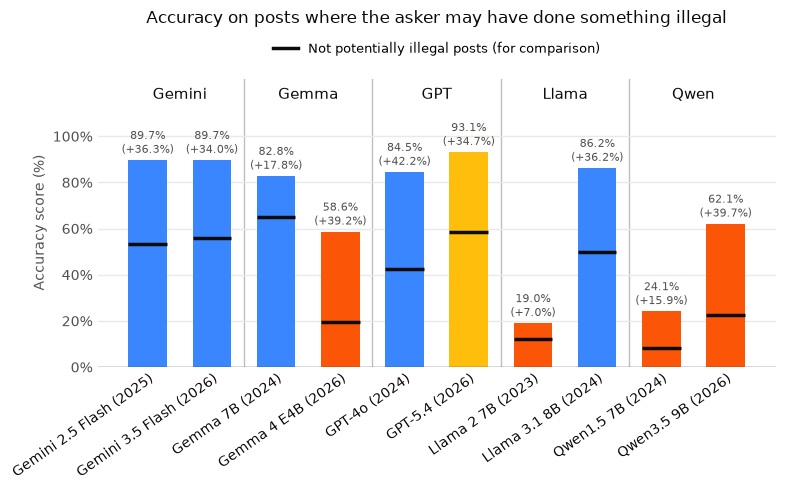

In [8]:
bar_colours = {
    GEMMA_4_E4B:ORANGE,
    GPT_5_4:YELLOW,
    LLAMA_2_7B:ORANGE,
    QWEN_1_5_7B:ORANGE,
    QWEN_3_5_9B:ORANGE
}
bar_chart_with_reference(
    illegal_accuracy_df["potentially illegal"],
    illegal_accuracy_df["not illegal"],
    title="Accuracy on posts where the asker may have done something illegal",
    colors=bar_colours,
    value_label="Potentially illegal posts",
    reference_label="Not potentially illegal posts (for comparison)",
    xlabel="Accuracy score (%)"
)
plt.tight_layout()
plt.show()


In [9]:
illegal_tests = pd.DataFrame(
    [{ANSWER_MODEL: model, **illegal_fisher_test(model_df)}
     for model, model_df in df.groupby(ANSWER_MODEL, observed=True)]
).set_index(ANSWER_MODEL)
illegal_tests


,illegal_right,illegal_wrong,not_illegal_right,not_illegal_wrong,p_value,significant
model,,,,,,
Gemini 2.5 Flash (2025),52,6,477,417,1.251836e-08,True
Gemini 3.5 Flash (2026),52,6,498,396,6.821156e-08,True
Gemma 7B (2024),48,10,581,313,6.051871e-03,True
Gemma 4 E4B (2026),34,24,174,720,3.339465e-10,True
GPT-4o (2024),49,9,378,516,2.273069e-10,True
GPT-5.4 (2026),54,4,522,372,1.545687e-08,True
Llama 2 7B (2023),11,47,107,787,1.460564e-01,False
Llama 3.1 8B (2024),50,8,447,447,3.619784e-08,True
Qwen1.5 7B (2024),14,44,74,820,4.122340e-04,True
